In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('insurance.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df = df.drop('region', axis=1)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(2)
memory usage: 62.8+ KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df

,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520
...,...,...,...,...,...,...
1333,50,male,30.970,3,no,10600.54830
1334,18,female,31.920,0,no,2205.98080
1335,18,female,36.850,0,no,1629.83350
1336,21,female,25.800,0,no,2007.94500


In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
charges     0
dtype: int64

In [10]:
df.duplicated().sum()

1

In [11]:
df= df.drop_duplicates()

In [12]:
df.duplicated().sum()

0

In [13]:
df.shape

(1337, 6)

Text(0.5, 1.0, 'Biểu đồ biểu diễn quan hệ giữa Tuổi và Phí bảo hiểm')

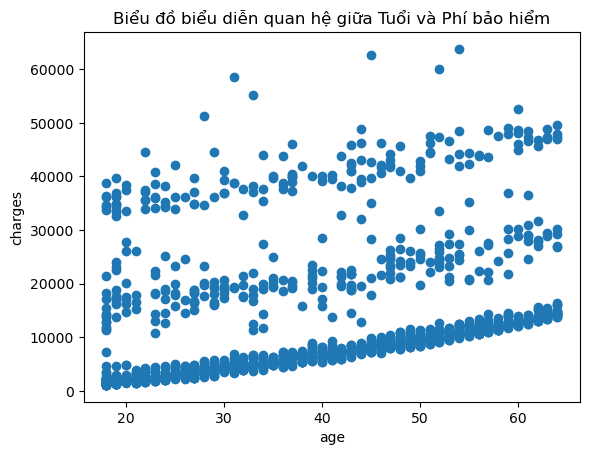

In [14]:
plt.scatter(df['age'], df['charges'])
plt.xlabel('age')
plt.ylabel('charges')
plt.title('Biểu đồ biểu diễn quan hệ giữa Tuổi và Phí bảo hiểm')

In [15]:
# Đánh giá mối tương quan
corr_age_charges = df['age'].corr(df['charges'])
print('Hệ số tương quan giữa age và chares:', corr_age_charges)

Hệ số tương quan giữa age và chares: 0.2983082125097864


**Tương quan mức độ thấp**

Text(0.5, 1.0, 'Biểu đồ biểu diễn quan hệ giữa BMI và Phí bảo hiểm')

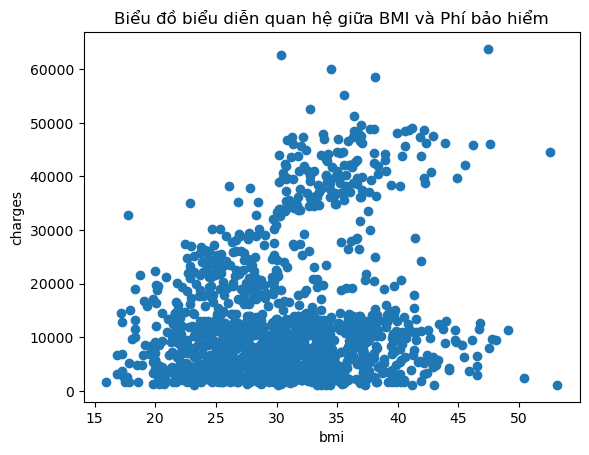

In [16]:
plt.scatter(df['bmi'], df['charges'])
plt.xlabel('bmi')
plt.ylabel('charges')
plt.title('Biểu đồ biểu diễn quan hệ giữa BMI và Phí bảo hiểm')

In [17]:
corr_bmi_charges = df['bmi'].corr(df['charges'])
print('Hệ số tương quan giữa BMI và charges:', corr_bmi_charges)

Hệ số tương quan giữa BMI và charges: 0.19840083122624938


**Tương quan mức độ thấp**

Text(0.5, 1.0, 'Biểu đồ biểu diễn quan hệ giữa Children và Phí bảo hiểm')

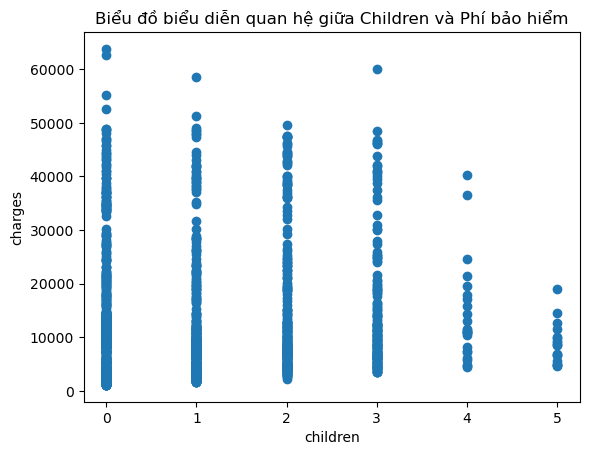

In [18]:
plt.scatter(df['children'], df['charges'])
plt.xlabel('children')
plt.ylabel('charges')
plt.title('Biểu đồ biểu diễn quan hệ giữa Children và Phí bảo hiểm')

In [19]:
corr_child_charges = df['children'].corr(df['charges'])
print('Hệ số tương quan giữa children và charges:', corr_child_charges)

Hệ số tương quan giữa children và charges: 0.06738935083963243


<Axes: xlabel='sex', ylabel='charges'>

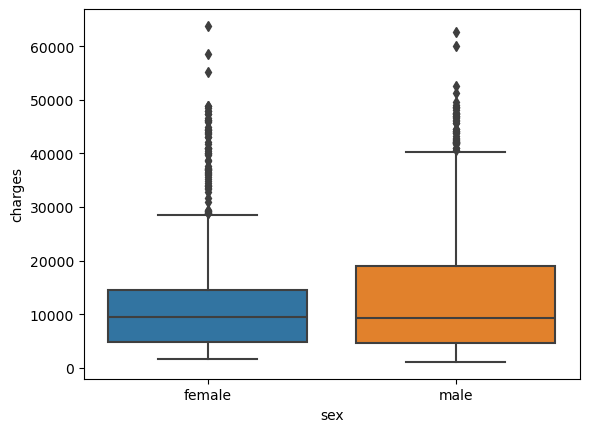

In [20]:
import seaborn as sns
sns.boxplot(x='sex', y='charges', data=df)

In [21]:
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})

In [22]:
corr_sex_charges = df['sex'].corr(df['charges'])
print('Hệ số tương quan giữa giới tính và charges:', corr_sex_charges)

Hệ số tương quan giữa giới tính và charges: 0.05804449579031291


<Axes: xlabel='smoker', ylabel='charges'>

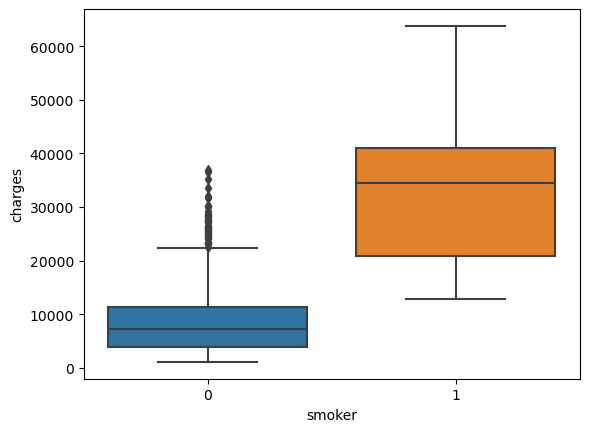

In [23]:
sns.boxplot(x='smoker', y='charges', data=df)

In [24]:
corr_smoker_charges = df['smoker'].corr(df['charges'])
print('Hệ số tương quan giữa smoker và charges:', corr_smoker_charges)

Hệ số tương quan giữa smoker và charges: 0.7872343672800323


**Tương quan mức độ cao**

In [25]:
df['sex'].value_counts()

sex
1    675
0    662
Name: count, dtype: int64

In [26]:
df['smoker'].value_counts()

smoker
0    1063
1     274
Name: count, dtype: int64

In [27]:
df

,age,sex,bmi,children,smoker,charges
0,19,0,27.900,0,1,16884.92400
1,18,1,33.770,1,0,1725.55230
2,28,1,33.000,3,0,4449.46200
3,33,1,22.705,0,0,21984.47061
4,32,1,28.880,0,0,3866.85520
...,...,...,...,...,...,...
1333,50,1,30.970,3,0,10600.54830
1334,18,0,31.920,0,0,2205.98080
1335,18,0,36.850,0,0,1629.83350
1336,21,0,25.800,0,0,2007.94500


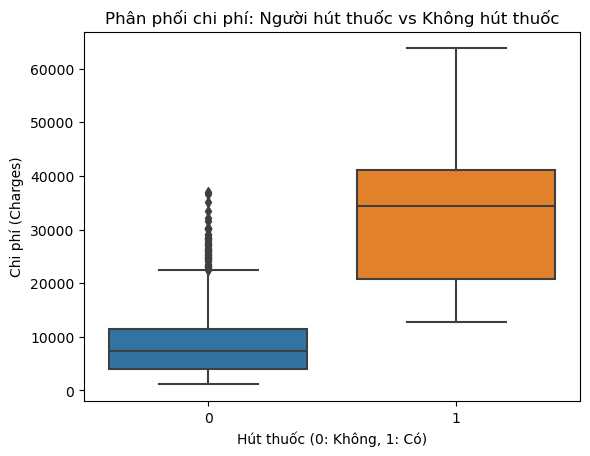

In [28]:
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Phân phối chi phí: Người hút thuốc vs Không hút thuốc')
plt.ylabel('Chi phí (Charges)')
plt.xlabel('Hút thuốc (0: Không, 1: Có)')
plt.show()

In [29]:
from sklearn.model_selection import train_test_split

X = df.drop('charges', axis=1)
y = df['charges']

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [32]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [33]:
print('Các hệ số hồi quy (w1..w5):', model.coef_)
print('Hệ số chặn w0:', model.intercept_)

Các hệ số hồi quy (w1..w5): [  249.09521752   -85.02704092   305.59649519   537.9633666
 23051.36812442]
Hệ số chặn w0: -11221.05166157084


#### Dự đoán trên tập Test

In [34]:
y_pred = model.predict(X_test)

In [35]:
# Tính phần dư
residuals = y_test - y_pred
residuals

900      908.766805
1064    -268.966390
1256   -2779.084860
298     7155.760365
237    -4760.444124
           ...     
534    -3175.446144
542    -1677.895818
760    -1976.738461
1284    8832.666167
1285     616.141475
Name: charges, Length: 268, dtype: float64

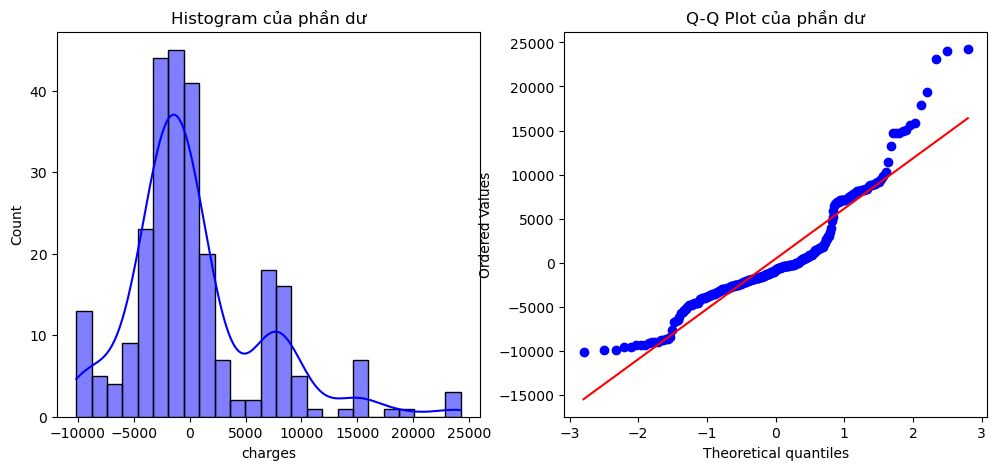

In [36]:
import scipy.stats as stats
plt.figure(figsize=(12, 5))

# Vẽ Histogram
plt.subplot(1, 2, 1)
sns.histplot(residuals, kde=True, color='blue')
plt.title('Histogram của phần dư')

# Vẽ Q-Q Plot
plt.subplot(1, 2, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot của phần dư')

plt.show()

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, max_error, r2_score

#Tính các sai số của mô hình:
MAE_model= mean_absolute_error(y_test, y_pred)
MSE_model= mean_squared_error(y_test, y_pred)
R2_model = r2_score(y_test, y_pred) 

import math
RMSE_model= math.sqrt(MSE_model)
print ('1. Sai số MAE của model: ', int(MAE_model))
print ('2. Sai số MSE của model: ', int(MSE_model))
print ('3. Sai số RMSE của model: ', int(RMSE_model))
print ('4. R2 Score của model: ', R2_model)

print ('Phí bảo hiểm dự đoán sai lớn nhất là:', max_error(y_test, y_pred))

1. Sai số MAE của model:  4198
2. Sai số MSE của model:  35901914
3. Sai số RMSE của model:  5991
4. R2 Score của model:  0.8046218811772661
Phí bảo hiểm dự đoán sai lớn nhất là: 24227.099974650693


In [39]:
from sklearn.metrics import mean_absolute_percentage_error

MAPE_model = mean_absolute_percentage_error(y_test, y_pred) * 100
print(f'5. MAPE: {MAPE_model:.2f}%')

# Kiểm tra phân phối sai số
residuals = y_test - y_pred
print(f'6. Độ lệch chuẩn của sai số: {residuals.std():.2f}')


5. MAPE: 42.00%
6. Độ lệch chuẩn của sai số: 5986.57
